In [ ]:
class LayerNorm1d: # (used to be BatchNorm1d)

    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

    def __call__(self, x):
        # calculate the forward pass
        xmean = x.mean(1, keepdim=True) # batch mean
        xvar = x.var(1, keepdim=True) # batch variance
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
        self.out = self.gamma * xhat + self.beta
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

torch.manual_seed(1337)
module = LayerNorm1d(100)
x = torch.randn(32, 100) # batch size 32 of 100-dimensional vectors
x = module(x)
x.shape

torch.Size([32, 100])

# Experiment: Scaling Laws for Data and Model Size

## Objective

Investigate whether increasing the training dataset requires a larger model to fully utilize the additional data.

## Background

Starting from the baseline nanoGPT model trained on the Tiny Shakespeare dataset, we increase the dataset size by approximately 2× by combining English text (Tiny Shakespeare) with Vietnamese poetry.

According to scaling laws, a larger dataset may benefit from a larger model capacity. The question is:

**When the amount of training data doubles, which model hyperparameter should be scaled?**

## Tasks

### Step 1: Baseline

Train the original nanoGPT model on the English-only dataset.

```python
n_embd = 64
n_head = 4
n_layer = 4
```

Record:

* Number of parameters
* Training loss
* Validation loss
* Generated samples

### Step 2: Increase Dataset Size

Combine the English and Vietnamese datasets and train the same model without changing any hyperparameters.

```python
n_embd = 64
n_head = 4
n_layer = 4
```

Compare the results with the baseline.

### Step 3: Scale the Model

Experiment with different model scaling strategies:

**Depth Scaling**

```python
n_embd = 64
n_head = 4
n_layer = 8
```

**Width Scaling**

```python
n_embd = 128
n_head = 4
n_layer = 4
```

**Depth + Width Scaling**

```python
n_embd = 128
n_head = 4
n_layer = 6
```

### Step 4: Analyze

Compare:

* Number of parameters
* Training loss
* Validation loss
* Training time
* Quality of generated text

## Discussion Questions

1. Does doubling the dataset improve performance without increasing model size?
2. Which hyperparameter contributes most to model capacity: `n_embd`, `n_layer`, or `n_head`?
3. Between increasing depth and width, which strategy is more effective?
4. Do the experimental results support the idea behind scaling laws?


In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.cuda.empty_cache()
import random
import requests
from datasets import load_dataset

dataset = load_dataset("truongpdd/vietnamese_poetry")

vi_docs = dataset["train"]["text"]

In [ ]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
en_text = requests.get(url).text

In [ ]:
len(en_text) # chỉ có khoảng 1.1 triệu ký tự

1115394

In [ ]:
print("Ratio of Vi:En", len(' '.join(vi_docs)) /  len(en_text))
# Do tập dữ liệu tiếng Việt gấp 74 lần tiếng Anh --> tăng tiếng Anh

Ratio of Vi:En 74.82052799279896


## Version 1: Train with default hyperparameters

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.cuda.empty_cache()
import random
import requests

# hyperparameters
batch_size = 16 # how many independent sequences will we process in parallel?
block_size = 32 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64 # Default của Karpathy
n_head = 4 # Default của Karpathy
n_layer = 4 # Default của Karpathy
dropout = 0.0
# ------------

torch.manual_seed(1337)
all_results = {}

# Download and load the tiny shakespeare dataset
from datasets import load_dataset

dataset = load_dataset("truongpdd/vietnamese_poetry")
vi_docs = dataset["train"]["text"]

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
en_text = requests.get(url).text
en_text = (en_text + "\n") * 74
en_docs = en_text.split("\n\n")
# Gộp các document
docs = []

docs.extend([("[EN]", d) for d in en_docs if len(d.strip()) > 0])
docs.extend([("[VI]", d) for d in vi_docs if len(d.strip()) > 0])

random.shuffle(docs)

# Chia train/val
split_idx = int(0.9 * len(docs))

train_docs = docs[:split_idx]
val_docs = docs[split_idx:]

# Sau đó mới nối lại
train_text = "\n\n".join(f"{lang}\n{doc}" for lang, doc in train_docs)
val_text = "\n\n".join(f"{lang}\n{doc}" for lang, doc in val_docs)

# here are all the unique characters that occur in this text
full_text = train_text + val_text

chars = sorted(list(set(full_text)))
vocab_size = len(chars)

stoi = {ch:i for i,ch in enumerate(chars)}
itos = {i:ch for i,ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos[i] for i in l)

# Encode riêng
train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data   = torch.tensor(encode(val_text), dtype=torch.long)



# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

# super simple bigram model
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C)
        x = tok_emb + pos_emb # (B,T,C)
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)
        logits = self.lm_head(x) # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # get the predictions
            logits, loss = self(idx_cond)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# create a PyTorch optimizer
history = {
    "step": [],
    "train_loss": [],
    "val_loss": []
}
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
      losses = estimate_loss()

      history["step"].append(iter)
      history["train_loss"].append(losses["train"].item())
      history["val_loss"].append(losses["val"].item())

      print(
          f"step {iter}: "
          f"train loss {losses['train']:.4f}, "
          f"val loss {losses['val']:.4f}"
      )

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# generate from the model
# context = torch.zeros((1, 1), dtype=torch.long, device=device)
# print(decode(m.generate(context, max_new_tokens=2000)[0].tolist()))
all_results[f"E{n_embd}_L{n_layer}"] = history

0.231143 M parameters
step 0: train loss 5.6239, val loss 5.6205
step 100: train loss 3.0990, val loss 3.0888
step 200: train loss 2.6519, val loss 2.6483
step 300: train loss 2.4736, val loss 2.4765
step 400: train loss 2.3624, val loss 2.3775
step 500: train loss 2.3082, val loss 2.3194
step 600: train loss 2.2543, val loss 2.2614
step 700: train loss 2.2204, val loss 2.2218
step 800: train loss 2.1994, val loss 2.2097
step 900: train loss 2.1762, val loss 2.1716
step 1000: train loss 2.1563, val loss 2.1538
step 1100: train loss 2.1264, val loss 2.1344
step 1200: train loss 2.1204, val loss 2.1048
step 1300: train loss 2.1014, val loss 2.0914
step 1400: train loss 2.0754, val loss 2.0802
step 1500: train loss 2.0636, val loss 2.0657
step 1600: train loss 2.0567, val loss 2.0456
step 1700: train loss 2.0374, val loss 2.0385
step 1800: train loss 2.0208, val loss 2.0183
step 1900: train loss 2.0057, val loss 2.0017
step 2000: train loss 1.9855, val loss 1.9869
step 2100: train loss 1.

In [ ]:
context = torch.tensor([encode('[VI]')], dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=100)[0].tolist()))

[VI]
thơ tám chữ: 
bóng hoa về thản thôi gập ninhiêng
trời tôi đôi vượn học đi không
tinh tháng đua đườn


In [ ]:
context = torch.tensor([encode('[EN]')], dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=100)[0].tolist()))

[EN]
Whick?

[EN]
GUMIO:
Tis ust measiours wit his suppiching to good.
'Till the herew's mudtish reichil


## Version 2: Train with ``wider`` embedding size

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.cuda.empty_cache()
import random
import requests

# hyperparameters
batch_size = 16 # how many independent sequences will we process in parallel?
block_size = 32 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 96 # from 64 to 96: thầy Tiếp sửa lại để tương thích với dữ liệu mới gồm tiếng Anh và tiếng Việt
n_head = 4
n_layer = 4
dropout = 0.0
# ------------

torch.manual_seed(1337)

# Download and load the tiny shakespeare dataset
from datasets import load_dataset

dataset = load_dataset("truongpdd/vietnamese_poetry")
vi_docs = dataset["train"]["text"]

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
en_text = requests.get(url).text
en_text = (en_text + "\n") * 74
en_docs = en_text.split("\n\n")
# Gộp các document
docs = []

docs.extend([("[EN]", d) for d in en_docs if len(d.strip()) > 0])
docs.extend([("[VI]", d) for d in vi_docs if len(d.strip()) > 0])

random.shuffle(docs)

# Chia train/val
split_idx = int(0.9 * len(docs))

train_docs = docs[:split_idx]
val_docs = docs[split_idx:]

# Sau đó mới nối lại
train_text = "\n\n".join(f"{lang}\n{doc}" for lang, doc in train_docs)
val_text = "\n\n".join(f"{lang}\n{doc}" for lang, doc in val_docs)

# here are all the unique characters that occur in this text
full_text = train_text + val_text

chars = sorted(list(set(full_text)))
vocab_size = len(chars)

stoi = {ch:i for i,ch in enumerate(chars)}
itos = {i:ch for i,ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos[i] for i in l)

# Encode riêng
train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data   = torch.tensor(encode(val_text), dtype=torch.long)



# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

# super simple bigram model
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C)
        x = tok_emb + pos_emb # (B,T,C)
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)
        logits = self.lm_head(x) # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # get the predictions
            logits, loss = self(idx_cond)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# create a PyTorch optimizer
history = {
    "step": [],
    "train_loss": [],
    "val_loss": []
}
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
      losses = estimate_loss()

      history["step"].append(iter)
      history["train_loss"].append(losses["train"].item())
      history["val_loss"].append(losses["val"].item())

      print(
          f"step {iter}: "
          f"train loss {losses['train']:.4f}, "
          f"val loss {losses['val']:.4f}"
      )

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# generate from the model
# context = torch.zeros((1, 1), dtype=torch.long, device=device)
# print(decode(m.generate(context, max_new_tokens=2000)[0].tolist()))
all_results[f"E{n_embd}_L{n_layer}"] = history

0.494055 M parameters
step 0: train loss 5.6744, val loss 5.6746
step 100: train loss 2.8038, val loss 2.8011
step 200: train loss 2.5059, val loss 2.5016
step 300: train loss 2.3550, val loss 2.3487
step 400: train loss 2.2681, val loss 2.2751
step 500: train loss 2.2099, val loss 2.2118
step 600: train loss 2.1686, val loss 2.1712
step 700: train loss 2.1274, val loss 2.1225
step 800: train loss 2.0989, val loss 2.1051
step 900: train loss 2.0746, val loss 2.0783
step 1000: train loss 2.0451, val loss 2.0493
step 1100: train loss 2.0268, val loss 2.0187
step 1200: train loss 2.0054, val loss 2.0063
step 1300: train loss 1.9928, val loss 1.9876
step 1400: train loss 1.9682, val loss 1.9662
step 1500: train loss 1.9633, val loss 1.9516
step 1600: train loss 1.9420, val loss 1.9346
step 1700: train loss 1.9220, val loss 1.9287
step 1800: train loss 1.9148, val loss 1.9148
step 1900: train loss 1.8905, val loss 1.9071
step 2000: train loss 1.8768, val loss 1.8855
step 2100: train loss 1.

In [ ]:
context = torch.tensor([encode('[VI]')], dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=100)[0].tolist()))

[VI]
thơ lục bát: 
 ước hắt trọi hạnh kia
mình trầu trôi cảng dửng phượng

khéo tha khèm nao khia
ngồi e


In [ ]:
context = torch.tensor([encode('[EN]')], dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=100)[0].tolist()))

[EN]
LADY MENENESCA:
No! I befuch rooble shall saugand;
Forly the repeath thou hear; away, hat
Nonour's 


## Version 3: Train with a ``deeper`` layers GPT

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.cuda.empty_cache()
import random
import requests

# hyperparameters
batch_size = 16 # how many independent sequences will we process in parallel?
block_size = 32 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 8 # from 4 to 8: Thầy Tiệp tăng n_layer lên để tương thích với quy mô của dữ liệu mới
dropout = 0.0
# ------------

torch.manual_seed(1337)

# Download and load the tiny shakespeare dataset
from datasets import load_dataset

dataset = load_dataset("truongpdd/vietnamese_poetry")
vi_docs = dataset["train"]["text"]

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
en_text = requests.get(url).text
en_text = (en_text + "\n") * 74
en_docs = en_text.split("\n\n")
# Gộp các document
docs = []

docs.extend([("[EN]", d) for d in en_docs if len(d.strip()) > 0])
docs.extend([("[VI]", d) for d in vi_docs if len(d.strip()) > 0])

random.shuffle(docs)

# Chia train/val
split_idx = int(0.9 * len(docs))

train_docs = docs[:split_idx]
val_docs = docs[split_idx:]

# Sau đó mới nối lại
train_text = "\n\n".join(f"{lang}\n{doc}" for lang, doc in train_docs)
val_text = "\n\n".join(f"{lang}\n{doc}" for lang, doc in val_docs)

# here are all the unique characters that occur in this text
full_text = train_text + val_text

chars = sorted(list(set(full_text)))
vocab_size = len(chars)

stoi = {ch:i for i,ch in enumerate(chars)}
itos = {i:ch for i,ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos[i] for i in l)

# Encode riêng
train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data   = torch.tensor(encode(val_text), dtype=torch.long)



# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B,T,C = x.shape
        k = self.key(x)   # (B,T,C)
        q = self.query(x) # (B,T,C)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,C)
        out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

# super simple bigram model
class BigramLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C)
        x = tok_emb + pos_emb # (B,T,C)
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)
        logits = self.lm_head(x) # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # get the predictions
            logits, loss = self(idx_cond)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# create a PyTorch optimizer
history = {
    "step": [],
    "train_loss": [],
    "val_loss": []
}
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
      losses = estimate_loss()

      history["step"].append(iter)
      history["train_loss"].append(losses["train"].item())
      history["val_loss"].append(losses["val"].item())

      print(
          f"step {iter}: "
          f"train loss {losses['train']:.4f}, "
          f"val loss {losses['val']:.4f}"
      )

    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

# generate from the model
# context = torch.zeros((1, 1), dtype=torch.long, device=device)
# print(decode(m.generate(context, max_new_tokens=2000)[0].tolist()))
all_results[f"E{n_embd}_L{n_layer}"] = history

0.430311 M parameters
step 0: train loss 5.5627, val loss 5.5627
step 100: train loss 3.0162, val loss 3.0194
step 200: train loss 2.5924, val loss 2.5944
step 300: train loss 2.4353, val loss 2.4366
step 400: train loss 2.3254, val loss 2.3338
step 500: train loss 2.2789, val loss 2.2815
step 600: train loss 2.2245, val loss 2.2210
step 700: train loss 2.1949, val loss 2.1895
step 800: train loss 2.1805, val loss 2.1632
step 900: train loss 2.1493, val loss 2.1439
step 1000: train loss 2.1095, val loss 2.1203
step 1100: train loss 2.1094, val loss 2.0964
step 1200: train loss 2.0902, val loss 2.0764
step 1300: train loss 2.0531, val loss 2.0596
step 1400: train loss 2.0422, val loss 2.0390
step 1500: train loss 2.0304, val loss 2.0235
step 1600: train loss 2.0066, val loss 2.0158
step 1700: train loss 1.9855, val loss 1.9861
step 1800: train loss 1.9784, val loss 1.9675
step 1900: train loss 1.9562, val loss 1.9647
step 2000: train loss 1.9592, val loss 1.9587
step 2100: train loss 1.

In [ ]:
context = torch.tensor([encode('[VI]')], dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=100)[0].tolist()))

[VI]
thơ tữ: 

lạt bóng hoa mặt son thôm gập
niệm kấp trời tôi đã nhưng học đi không
tinh thận hàng đườn


In [ ]:
context = torch.tensor([encode('[EN]')], dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=100)[0].tolist()))

[EN]
BATEN?

[EN]
GUTEDHAND:
AN, I durke strue have their my cese post; hill the here-noves,
Merrr ithil


## Plot loss diagram


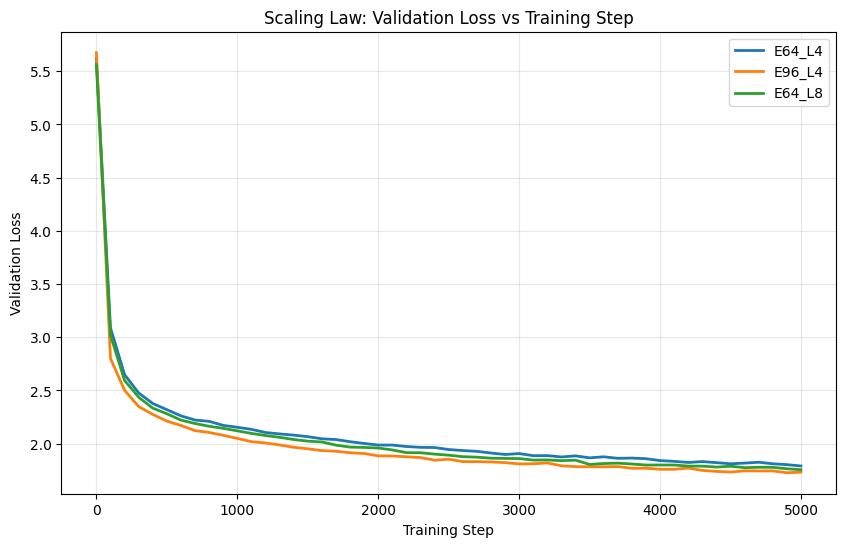

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

for config_name, history in all_results.items():

    plt.plot(
        history["step"],
        history["val_loss"],
        linewidth=2,
        label=config_name
    )

plt.xlabel("Training Step")
plt.ylabel("Validation Loss")
plt.title("Scaling Law: Validation Loss vs Training Step")
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

The results show that increasing the ``model size`` improves validation loss. Larger models are able to absorb and utilize the training data more effectively.